In [1]:
import numpy as np
import xarray as xr
import cftime
import pandas as pd
from scipy import stats

import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from matplotlib.colors import LinearSegmentedColormap, BoundaryNorm
from matplotlib.patches import Rectangle
import matplotlib.colors as mcolors


import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter


path_godas = r'C:\Users\jiuwe\study\data\Godas\\'       
path_soda = r'../../../study/data/soda/'         
path_ncep = r'C:\Users\jiuwe\study\data\necp\monthly\\' 
path_noaa = r'C:\Users\jiuwe\study\data\noaa-20c\\'
path_oa = r'C:\Users\jiuwe\study\data\OAFlux_v3\\'

lon = np.arange(120, 281, 1)
lat = np.arange(-40, 41, 1)

In [2]:
# mixed layer heat budget equation
# take the mixed layer depth equal to 46.61m
# unit: K/month
level_u = np.array([5.01, 15.07, 25.28, 35.76, 46.61, 57.98, 70.02, 82.92, 96.92, 112.32, 129.49, 148.96, 171.4, 197.79])
ds_u = xr.open_dataset(path_soda+'soda.ucur.nc').rename({'TIME':'time'}).assign_coords({'level':level_u})
ds_v = xr.open_dataset(path_soda+'soda.vcur.nc').rename({'TIME':'time'}).assign_coords({'level':level_u})
ds_w = xr.open_dataset(path_soda+'soda.wcur.nc').rename({'TIME':'time'}).assign_coords({'level':level_u})
ds_t = xr.open_dataset(path_soda+'soda.temp.nc').rename({'TIME':'time'}).assign_coords({'level':level_u})

ucur = ds_u.U.loc[:, :50, :, :].mean(dim='level')
vcur = ds_v.V.loc[:, :50, :, :].mean(dim='level')
wcur = ds_w.W[:, 4, :, :]
temp = ds_t.TEMP.loc[:, :60, :, :]


In [20]:
U = ucur.groupby('time.month').mean()
U = U.sel(month=ucur.time.dt.month)
u = ucur - U

V = vcur.groupby('time.month').mean()
V = V.sel(month=vcur.time.dt.month)
v = vcur - V

T = temp.mean(dim='level').groupby('time.month').mean()
T = T.sel(month=temp.time.dt.month)
t = temp.mean(dim='level') - T

W = wcur.groupby('time.month').mean()
W = W.sel(month=wcur.time.dt.month)
w = wcur - W

Th = temp[:, 5, :, :].groupby('time.month').mean()
Th = Th.sel(month=temp.time.dt.month)
th = temp[:, 5, :, :] - Th

In [21]:
time = pd.date_range('1900-01', '2010-12', freq='MS')
nt, ny, nx = len(time), len(lat), len(lon)
a = 6.4e+6
H = 46.61
dz = 57.98 - H/2
# term = ['dT/dt', '-Utx', '-uTx', '-utx', '-Vty', '-vTy', '-vty', '-Wtz', '-wTz', '-wtz', 'SW', 'LW', 'SH', 'LH', 'R']
term = ['dT/dt', '-Utx', '-uTx', '-utx', '-Vty', '-vTy', '-vty', '-Wtz', '-wTz', '-wtz', 'R']
nterm = len(term)

In [22]:
ds_dTdt = xr.Dataset(
   {
       'MLHB':(['time', 'term', 'lat', 'lon'], np.empty((nt, nterm, ny, nx))),
       'u':(['time', 'dir','lat', 'lon'], np.empty((nt, 3, ny, nx))),
       'U':(['time', 'dir', 'lat', 'lon'], np.empty((nt, 3, ny, nx))),
       'dt':(['time', 'dir', 'lat', 'lon'], np.empty((nt, 3, ny, nx))),
       'dT':(['time', 'dir', 'lat', 'lon'], np.empty((nt, 3, ny, nx))),
   },
   coords={
        'time':(['time'], time),
        'dir':(['dir'], ['u', 'v', 'w']),
        'term':(['term'], term),
        'lat':(['lat'], lat),
        'lon':(['lon'], lon)
    }
)

ds_dTdt.MLHB[:, 0] = t.assign_coords({'time':np.arange(nt)}).differentiate('time').values

fac = 30*24*3600/(np.pi/180*a)
ds_dTdt.MLHB[:, 1] = (-U*t.differentiate('lon')).values*fac
ds_dTdt.MLHB[:, 2] = (-u*T.differentiate('lon')).values*fac
ds_dTdt.MLHB[:, 3] = (-u*t.differentiate('lon')).values*fac

ds_dTdt.MLHB[:, 4] = (-V*t.differentiate('lat')).values*fac
ds_dTdt.MLHB[:, 5] = (-v*T.differentiate('lat')).values*fac
ds_dTdt.MLHB[:, 6] = (-v*t.differentiate('lat')).values*fac

fac = 30*24*3600
ds_dTdt.MLHB[:, 7] = (-W*(t - th)/dz).values * fac
ds_dTdt.MLHB[:, 8] = (-w*(T - Th)/dz).values * fac
ds_dTdt.MLHB[:, 9] = (-w*(t - th)/dz).values * fac

ds_dTdt.MLHB[:, -1] = ds_dTdt.MLHB[:, 0] - ds_dTdt.MLHB[:, 1:-1].sum(dim='term')

fac = 1/(np.pi/180*a)
ds_dTdt.u[:, 0], ds_dTdt.u[:, 1], ds_dTdt.u[:, 2] = u.values, v.values, w.values
ds_dTdt.U[:, 0], ds_dTdt.U[:, 1], ds_dTdt.U[:, 2] = U.values, V.values, W.values
ds_dTdt.dt[:, 0], ds_dTdt.dt[:, 1], ds_dTdt.dt[:, 2] = (t.differentiate('lon')).values*fac, (t.differentiate('lat')).values*fac, ((t - th)/dz).values
ds_dTdt.dT[:, 0], ds_dTdt.dT[:, 1], ds_dTdt.dT[:, 2] = (T.differentiate('lon')).values*fac, (T.differentiate('lat')).values*fac, ((T - Th)/dz).values



ds_dTdt.to_netcdf('./data/dTdt.nc')

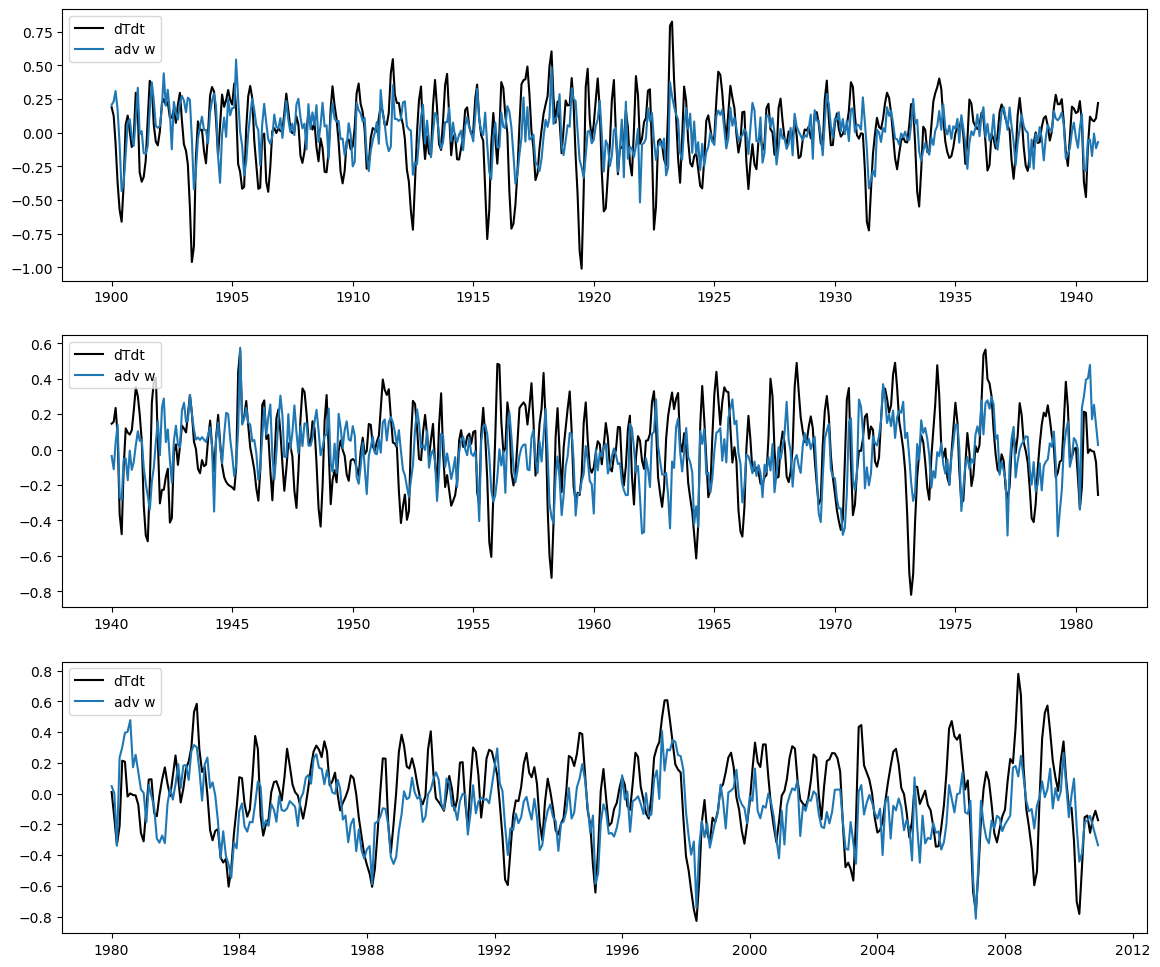

In [92]:
fig, axs = plt.subplots(3 ,1, figsize=(14, 12))
mlhb = ds_dTdt.MLHB.loc[:, :, -5:5, 180:280].mean(dim=['lat', 'lon'])
datas = [mlhb.loc[:'1940'], mlhb.loc['1940':'1980'], mlhb.loc['1980':]]
for i in range(3):
    ax = axs[i]
    data = datas[i]
    ax.plot(data.time, data[:, 0], color='k', label='dTdt')
    # ax.plot(data.time, data[:, 1:4].sum(dim='term'), label='adv u')
    # ax.plot(data.time, data[:, 4:7].sum(dim='term'), label='adv v')
    ax.plot(data.time, data[:, 7:10].sum(dim='term'), label='adv w')
    # ax.plot(data.time, data[:, 1:14].sum(dim='term'), color='r', label='mlhb')
    # ax.plot(data.time, data[:, 1:10].sum(dim='term'), label='adv')
    # ax.plot(data.time, data[:, -1:].sum(dim='term'), label='hflx')
    ax.legend(loc='upper left')

In [23]:
cp = np.fromfile('./data/CP.txt', dtype='<U48').astype('datetime64[M]')
ep = np.fromfile('./data/EP.txt', dtype='<U48').astype('datetime64[M]')
mix = np.fromfile('./data/MIX.txt', dtype='<U48').astype('datetime64[M]')
suc = np.fromfile('./data/SUC.txt', dtype='<U48').astype('datetime64[M]')
end = np.datetime64('2009-01')
cp = cp[cp < end]
ep = ep[ep < end]
mix = mix[mix < end]
suc = suc[suc < end]
events = [mix, ep, cp, suc]

mon = np.arange(-6, 30)
nt, ny, nx = len(mon), len(lat), len(lon)

ds_nino = xr.Dataset(
    {
        'MLHB':(['type', 'month', 'term', 'lat', 'lon'], np.empty((4, nt, len(term), ny, nx))),
        'u':(['type', 'month', 'dir', 'lat', 'lon'], np.empty((4, nt, 3, ny, nx))),
        'U':(['type', 'month', 'dir', 'lat', 'lon'], np.empty((4, nt, 3, ny, nx))),
        'dt':(['type', 'month', 'dir', 'lat', 'lon'], np.empty((4, nt, 3, ny, nx))),
        'dT':(['type', 'month', 'dir', 'lat', 'lon'], np.empty((4, nt, 3, ny, nx))),
        
    },
    coords={
        'type':(['type'], ['MIX', 'CP', 'EP', 'SUC']),
        'dir':(['dir'], ['u', 'v', 'w']),
        'month':(['month'], mon),
        'term':(['term'], term),
        'lat':(['lat'], lat),
        'lon':(['lon'], lon)
    }
)
for i in range(4):
    event = events[i]
    for j in range(nt):
        ds_nino.MLHB[i, j] = ds_dTdt.MLHB.loc[(events[i] + np.timedelta64(mon[j], "M")).astype('datetime64[ns]')].mean(dim='time').values
        ds_nino.u[i, j] = ds_dTdt.u.loc[(events[i] + np.timedelta64(mon[j], "M")).astype('datetime64[ns]')].mean(dim='time').values
        ds_nino.U[i, j] = ds_dTdt.U.loc[(events[i] + np.timedelta64(mon[j], "M")).astype('datetime64[ns]')].mean(dim='time').values
        ds_nino.dt[i, j] = ds_dTdt.dt.loc[(events[i] + np.timedelta64(mon[j], "M")).astype('datetime64[ns]')].mean(dim='time').values
        ds_nino.dT[i, j] = ds_dTdt.dT.loc[(events[i] + np.timedelta64(mon[j], "M")).astype('datetime64[ns]')].mean(dim='time').values
ds_nino.to_netcdf('./data/composite_dTdt.nc')


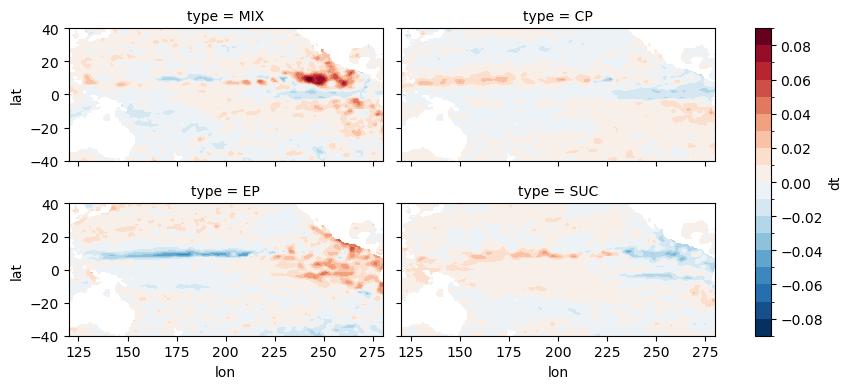

In [25]:
ds_nino.dt[:, 10, 2, :, :].plot.contourf(levels=21, col='type', col_wrap=2, size=2, aspect=2)

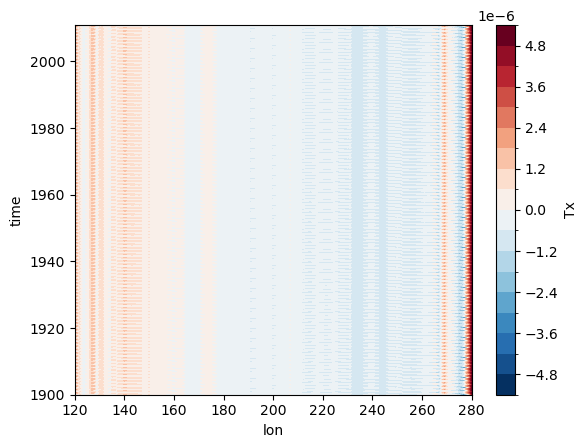

In [17]:
ds_dTdt.Tx.loc[:, -5:5, :].mean(dim='lat').plot.contourf(levels=21)